# NexuStock · Análisis exploratorio de datos

| | |
|---|---|
| **Proyecto** | NexuStock: gestión y predicción de inventario para una carnicería independiente |
| **Entregable** | Informe EDA · Kanban v3, tarea 25 |
| **Responsable** | Manuel Bustamante (Data Scientist) |
| **Periodo analizado** | 2022-01-01 a 2023-12-31 (conjunto de entrenamiento) |

## Objetivo

Caracterizar la demanda de los 24 productos de la carnicería y verificar los patrones que justifican las variables exigidas por el ERS para el modelo de regresión: estacionalidad, eventos del calendario, días de pago, tendencia y ventas de semanas anteriores. El análisis también identifica la censura de la venta por quiebres de stock, que condiciona la interpretación del error del modelo.

## Datos

El conjunto cubre de enero de 2022 a diciembre de 2024, con precios de referencia actualizados según el IPC del INE y el calendario de feriados de Chile.

| Archivo | Contenido | Uso en este notebook |
|---|---|---|
| `raw/AAAA/ventas_AAAA.csv` | Una fila por línea de venta | Análisis de demanda |
| `raw/AAAA/compras_AAAA.csv` | Pedidos recibidos de proveedores | Reconstrucción del stock |
| `raw/AAAA/mermas_AAAA.csv` | Producto dado de baja | Reconstrucción del stock |
| `raw/productos.csv` | Catálogo de 24 productos en 5 categorías | Atributos de producto |
| `raw/calendario_eventos.csv` | Feriados y eventos 2022-2024 | Análisis de eventos |
| `raw/inventario_inicial_2022-01-01.csv` | Stock inicial en bodega y en tránsito | Reconstrucción del stock |
| `evaluacion/demanda_diaria.csv` | Demanda total y venta perdida por quiebre | Solo validación (sección 12) |

> **Regla de evaluación.** El EDA y el entrenamiento usan solo 2022-2023. Los datos de 2024 se reservan como conjunto de prueba y se usan una sola vez, en el notebook 03, para calcular el MAE general y el MAE en festivos. En la plataforma, 2024 se carga semana a semana para mostrar las predicciones en el dashboard.

## 1. Configuración del entorno

Rutas relativas a la raíz de `ml-engine`, de modo que el notebook funcione en cualquier equipo que clone el repositorio.

In [45]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', '{:,.2f}'.format)
sns.set_theme(style='whitegrid')

BASE = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RAW = BASE / 'data' / 'raw'
PROCESSED = BASE / 'data' / 'processed'
PROCESSED.mkdir(parents=True, exist_ok=True)
print(RAW, RAW.exists())

#Este código hace que el notebook encuentre los datos, 
# visual ejecuta el notebook desde la carpeta notebooks, 
# pero si se ejecuta desde otra carpeta, no encuentra los datos. 
# Por eso se hace la verificación de la carpeta actual 
# y se ajusta la ruta de los datos según corresponda.



c:\Users\manu_\OneDrive\Escritorio\NexuStock\NexuStock\Codigo\ml-engine\data\raw True


## 2. Carga de datos y separación temporal

Se unen los tres años de ventas, compras y mermas, y se agrega la categoría de cada producto. A partir de aquí, `ventas` y `mermas` contienen solo el periodo de entrenamiento. Las versiones completas (`ventas_todas`, `mermas_todas`) se usan únicamente para reconstruir el stock en la sección 10.

In [46]:
def leer_anios(patron):
    return pd.concat([pd.read_csv(f) for f in sorted(RAW.glob(patron))], ignore_index=True)

FIN_ENTRENAMIENTO = pd.Timestamp('2023-12-31')

ventas_todas = leer_anios('20*/ventas_*.csv')
compras = leer_anios('20*/compras_*.csv')
mermas_todas = leer_anios('20*/mermas_*.csv')
productos = pd.read_csv(RAW / 'productos.csv')
calendario = pd.read_csv(RAW / 'calendario_eventos.csv', parse_dates=['fecha_inicio', 'fecha_fin'])
inventario = pd.read_csv(RAW / 'inventario_inicial_2022-01-01.csv', parse_dates=['fecha_recepcion'])

ventas_todas['fecha'] = pd.to_datetime(ventas_todas['fecha'])
mermas_todas['fecha'] = pd.to_datetime(mermas_todas['fecha'])
compras['fecha_pedido'] = pd.to_datetime(compras['fecha_pedido'])
compras['fecha_recepcion'] = pd.to_datetime(compras['fecha_recepcion'])

ventas_todas = ventas_todas.merge(productos[['producto_id', 'nombre_producto', 'categoria']],
                                  on='producto_id', how='left')

# El EDA usa solo el periodo de entrenamiento; 2024 queda reservado para la prueba
ventas = ventas_todas[ventas_todas['fecha'] <= FIN_ENTRENAMIENTO].copy()
mermas = mermas_todas[mermas_todas['fecha'] <= FIN_ENTRENAMIENTO].copy()

print('Ventas de entrenamiento:', ventas.shape)
print('Líneas de 2024 reservadas:', len(ventas_todas) - len(ventas))


Ventas de entrenamiento: (70781, 12)
Líneas de 2024 reservadas: 35443


## 3. Calidad de los datos

Revisión de valores nulos, duplicados, cantidades no válidas y consistencia entre cantidad, precio unitario y total de cada línea.

In [47]:
print('Nulos en ventas:', ventas.isna().sum().sum())
print('venta_id duplicados:', ventas['venta_id'].duplicated().sum())
print('Cantidades <= 0:', (ventas['cantidad_kg'] <= 0).sum())
print('Rango de fechas:', ventas['fecha'].min().date(), '->', ventas['fecha'].max().date())

diferencia = (ventas['cantidad_kg'] * ventas['precio_unitario_venta_clp']).round() - ventas['total_venta_clp']
print('Líneas con total distinto de kg x precio (más de 1 CLP):', (diferencia.abs() > 1).sum())

ventas['anio'] = ventas['fecha'].dt.year
ventas.groupby('anio')['cantidad_kg'].agg(lineas='count', kg='sum')


Nulos en ventas: 0
venta_id duplicados: 0
Cantidades <= 0: 0
Rango de fechas: 2022-01-02 -> 2023-12-31
Líneas con total distinto de kg x precio (más de 1 CLP): 0


,lineas,kg
anio,,
2022,34902,"41,271.41"
2023,35879,"42,334.74"


**Resultado.** No hay nulos, duplicados ni cantidades no válidas, y el total de cada línea coincide con cantidad × precio. Los datos no requieren imputación ni limpieza. El volumen anual es de 41.271 kg en 2022 y 42.335 kg en 2023 (+2,6 %). No hay ventas el 1 de enero porque el local cierra en los feriados irrenunciables.

## 4. Distribución de la venta por día de la semana

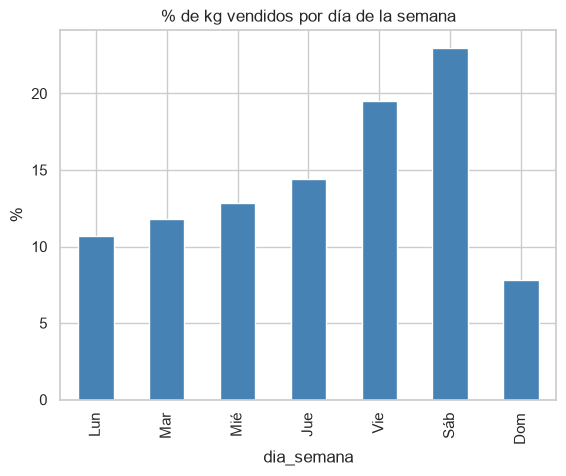

dia_semana
Lun   10.70
Mar   11.80
Mié   12.90
Jue   14.40
Vie   19.50
Sáb   23.00
Dom    7.80
Name: cantidad_kg, dtype: float64

In [48]:
dias = ['Lun', 'Mar', 'Mié', 'Jue', 'Vie', 'Sáb', 'Dom']
ventas['dia_semana'] = ventas['fecha'].dt.dayofweek

por_dia = ventas.groupby('dia_semana')['cantidad_kg'].sum()
por_dia_pct = (por_dia / por_dia.sum() * 100).rename(index=dict(enumerate(dias)))

ax = por_dia_pct.plot.bar(color='steelblue', title='% de kg vendidos por día de la semana')
ax.set_ylabel('%')
plt.show()
por_dia_pct.round(1)

#Este código prueba el comportamiento de las ventas por día de la semana, 
# para ver si hay algún patrón que pueda ser útil para el modelo.


**Resultado.** El viernes (19,5 %) y el sábado (23,0 %) concentran el 42,5 % de los kg vendidos en la semana. El domingo registra solo el 7,8 % porque el local atiende únicamente en la mañana.

Como el modelo predice demanda semanal, este patrón no entra como variable. Se usará después para repartir la demanda semanal entre los días y estimar la fecha de quiebre.

## 5. Serie semanal de ventas

Total de kg vendidos por semana (lunes a domingo). Las líneas rojas marcan el inicio de cada periodo de Fiestas Patrias.

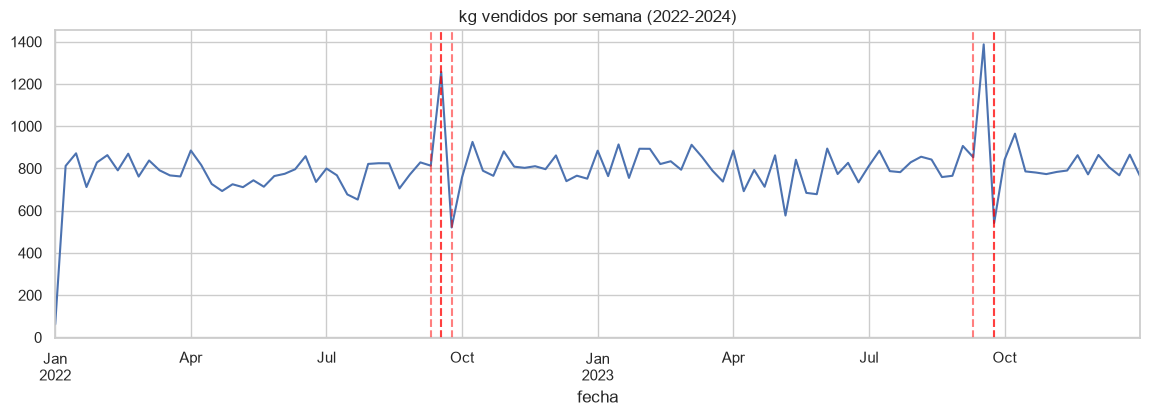

count     105.00
mean      796.00
std       127.00
min        62.00
25%       761.00
50%       793.00
75%       853.00
max     1,387.00
Name: cantidad_kg, dtype: float64


fecha
2023-09-17   1,387.00
2022-09-18   1,257.00
2023-10-08     965.00
2022-10-09     926.00
2023-01-15     914.00
Name: cantidad_kg, dtype: float64

In [49]:
semanal = ventas.set_index('fecha')['cantidad_kg'].resample('W-SUN').sum()

fig, ax = plt.subplots(figsize=(14, 4))
semanal.plot(ax=ax, title='kg vendidos por semana (2022-2024)')
for fecha in calendario.loc[calendario['tipo'] == 'fiestas_patrias', 'fecha_inicio']:
    ax.axvline(fecha, color='red', ls='--', alpha=0.5)
plt.show()

print(semanal.describe().round(0))
semanal.nlargest(5).round(0)

#Este otro código prueba como se ve la serie completa de ventas por semana, 
# y si hay picos en fechas especiales, como fiestas patrias.

**Resultado.** La venta semanal es estable en torno a 796 kg (mediana 793 kg, desviación estándar 127 kg). Las dos semanas de mayor venta corresponden a Fiestas Patrias: 1.387 kg en 2023 y 1.257 kg en 2022, equivalentes a 1,75 y 1,59 veces la mediana. El mínimo de 62 kg corresponde a una semana incompleta (solo el 2 de enero de 2022) y se excluye al construir el dataset semanal.

## 6. Tendencia por categoría

In [50]:
cat_anio = ventas.pivot_table(index='categoria', columns='anio', values='cantidad_kg', aggfunc='sum')
cat_anio['var_2022_2023_%'] = (cat_anio[2023] / cat_anio[2022] - 1) * 100
cat_anio.round(1)


anio,2022,2023,var_2022_2023_%
categoria,,,
Cerdo,"6,161.40","6,135.20",-0.40
Embutidos,"4,173.50","4,245.60",1.70
Pescados,"3,035.40","3,149.20",3.70
Pollo,"13,169.60","14,168.10",7.60
Vacuno,"14,731.50","14,636.60",-0.60


**Resultado.** Pollo crece 7,6 % entre 2022 y 2023. Las demás categorías varían menos de 4 %; Vacuno (−0,6 %) y Cerdo (−0,4 %) bajan levemente. La sustitución de carnes rojas por pollo, consistente con el alza de precios, justifica incluir un índice de tendencia (`t`) y la categoría como variables.

## 7. Estacionalidad mensual

Índice estacional por categoría: venta del mes dividida por el mes promedio de la categoría. Un valor de 1,20 indica una venta 20 % superior al promedio.

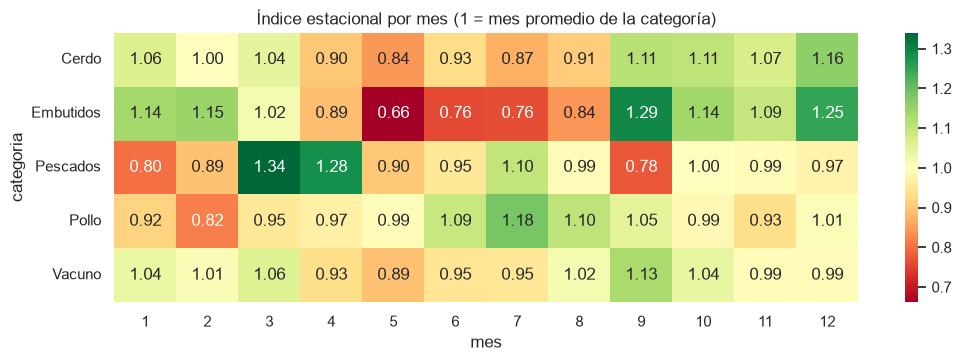

In [51]:
ventas['mes'] = ventas['fecha'].dt.month
mes_cat = ventas.pivot_table(index='categoria', columns='mes', values='cantidad_kg', aggfunc='sum')
indice_mes = mes_cat.div(mes_cat.mean(axis=1), axis=0)

plt.figure(figsize=(12, 3.5))
sns.heatmap(indice_mes, annot=True, fmt='.2f', cmap='RdYlGn', center=1)
plt.title('Índice estacional por mes (1 = mes promedio de la categoría)')
plt.show()


**Resultado.**

| Categoría | Patrón | Índice |
|---|---|---|
| Pescados | Alza en Cuaresma y Semana Santa | marzo 1,34 · abril 1,28 |
| Embutidos | Temporada de asados y Fiestas Patrias | septiembre 1,29 · mayo 0,66 |
| Pollo | Alza en invierno (guisos) | julio 1,18 |
| Cerdo | Alza en septiembre y diciembre | diciembre 1,16 |

La estacionalidad difiere entre categorías, por lo que el modelo debe combinar el mes o la semana del año con la categoría. Un modelo de árboles capta esta interacción de forma directa; una regresión lineal no.

## 8. Efecto de los eventos del calendario

Venta de los 7 días previos a cada fecha, dividida por la mediana semanal del año. Se usa una ventana móvil y no la semana calendario porque, cuando el 18 de septiembre cae a mitad de semana, la semana calendario mezcla los días de mayor venta con los días en que el local está cerrado.

In [52]:
def ratio_7_dias(df, fechas):
    """kg de los 7 días que terminan en cada fecha, dividido por la mediana semanal de ese año."""
    diario = df.groupby('fecha')['cantidad_kg'].sum().asfreq('D', fill_value=0)
    suma_7 = diario.rolling(7).sum()
    filas = []
    for f in pd.to_datetime(list(fechas)):
        mediana = diario[diario.index.year == f.year].resample('W-SUN').sum().median()
        filas.append({'hasta': f.date(), 'kg_7_dias': suma_7[f], 'mediana_semanal': mediana,
                      'ratio': suma_7[f] / mediana})
    return pd.DataFrame(filas)

previo_18 = [pd.Timestamp(a, 9, 17) for a in (2022, 2023)]
print('7 días previos al 18, todas las categorías:')
display(ratio_7_dias(ventas, previo_18).round(2))

es_viernes_santo = calendario['evento'].str.contains('Viernes Santo')
viernes_santo = calendario.loc[es_viernes_santo & (calendario['fecha_inicio'] <= FIN_ENTRENAMIENTO), 'fecha_inicio']
print('7 días hasta el Viernes Santo, solo Pescados:')
display(ratio_7_dias(ventas[ventas['categoria'] == 'Pescados'], viernes_santo).round(2))


7 días previos al 18, todas las categorías:


,hasta,kg_7_dias,mediana_semanal,ratio
0,2022-09-17,"1,331.33",790.88,1.68
1,2023-09-17,"1,387.44",793.68,1.75


7 días hasta el Viernes Santo, solo Pescados:


,hasta,kg_7_dias,mediana_semanal,ratio
0,2022-04-15,124.11,54.62,2.27
1,2023-04-07,118.92,58.99,2.02


**Resultado.**

| Evento | Alcance | 2022 | 2023 |
|---|---|---|---|
| 7 días previos al 18 de septiembre | Todas las categorías | 1,68 | 1,75 |
| 7 días hasta el Viernes Santo | Pescados | 2,27 | 2,02 |

Fiestas Patrias eleva la venta total cerca de 70 %, y Semana Santa duplica la venta de pescados. Ninguno de los dos efectos puede anticiparse con un promedio histórico, lo que justifica las variables `dias_hasta_18`, `fiestas_patrias`, `semana_santa` y `cuaresma`.

## 9. Efecto de los días de pago

Venta diaria promedio en inicio de mes (días 1-5), quincena (días 14-17) y fin de mes (día 28 en adelante), relativa al resto de los días. La comparación se hace dentro de cada día de la semana para aislar el efecto del pago del efecto del fin de semana.

In [53]:
diario = ventas.groupby('fecha')['cantidad_kg'].sum().to_frame('kg')
diario['dia_mes'] = diario.index.day
diario['dia_semana'] = diario.index.dayofweek
diario['tramo'] = np.select(
    [diario['dia_mes'] <= 5, diario['dia_mes'].between(14, 17), diario['dia_mes'] >= 28],
    ['inicio_mes', 'quincena', 'fin_mes'],
    default='resto',
)
efecto = diario.groupby(['dia_semana', 'tramo'])['kg'].mean().unstack()
efecto.div(efecto['resto'], axis=0).rename(index=dict(enumerate(dias))).round(2)


tramo,fin_mes,inicio_mes,quincena,resto
dia_semana,,,,
Lun,1.15,1.03,1.03,1.00
Mar,1.15,1.06,1.04,1.00
Mié,1.15,1.05,1.10,1.00
Jue,1.09,1.08,1.19,1.00
Vie,1.19,1.10,1.17,1.00
Sáb,1.13,1.02,1.12,1.00
Dom,1.05,1.11,1.09,1.00


**Resultado.** Los días de fin de mes venden entre 5 % y 19 % más que un día equivalente fuera de esos tramos, y la quincena entre 3 % y 19 %. El efecto es mayor el jueves y el viernes. En el dataset semanal se representa con las variables `quincena` y `fin_mes`, que indican si la semana contiene esas fechas.

## 10. Reconstrucción del stock diario

Balance diario por producto: inventario inicial + compras recibidas − ventas − mermas. Se calcula sobre los tres años porque el stock de un día depende solo de movimientos pasados y es información que el sistema conoce en todo momento; el notebook 02 lo necesita para el periodo de prueba.

In [54]:
fechas = pd.date_range('2022-01-01', '2024-12-31', freq='D')
grilla = pd.MultiIndex.from_product([productos['producto_id'], fechas], names=['producto_id', 'fecha'])

inv = inventario.rename(columns={'fecha_recepcion': 'fecha'})
inv['fecha'] = inv['fecha'].clip(lower=fechas[0])
entradas = pd.concat([
    compras.rename(columns={'fecha_recepcion': 'fecha'})[['producto_id', 'fecha', 'cantidad_kg']],
    inv[['producto_id', 'fecha', 'cantidad_kg']],
])

stock = pd.DataFrame(index=grilla)
stock['entra'] = entradas.groupby(['producto_id', 'fecha'])['cantidad_kg'].sum()
stock['vende'] = ventas_todas.groupby(['producto_id', 'fecha'])['cantidad_kg'].sum()
stock['merma'] = mermas_todas.groupby(['producto_id', 'fecha'])['cantidad_kg'].sum()
stock = stock.fillna(0)
stock['stock_cierre'] = (stock['entra'] - stock['vende'] - stock['merma']).groupby(level='producto_id').cumsum()

print('Stock mínimo reconstruido:', round(stock['stock_cierre'].min(), 3))
stock.groupby(level='producto_id')['stock_cierre'].last().round(2).head()

Stock mínimo reconstruido: -0.16


producto_id
P001    8.25
P002    5.98
P003    4.90
P004   10.09
P005    7.16
Name: stock_cierre, dtype: float64

**Resultado.** El stock mínimo reconstruido es de −0,16 kg, atribuible al redondeo de las cantidades. Un descuadre real produciría diferencias de decenas de kg. El balance de inventario es consistente.

## 11. Quiebres de stock y censura de la venta

Se marca como quiebre todo día en que un producto cierra con stock menor o igual a 0,05 kg. En esos días la venta observada es menor que la demanda real: la venta está censurada por el stock.

In [55]:
stock['quiebre'] = stock['stock_cierre'] <= 0.05

es_entrenamiento = stock.index.get_level_values('fecha') <= FIN_ENTRENAMIENTO
quiebre_ent = stock.loc[es_entrenamiento, 'quiebre']
dia_sem = quiebre_ent.index.get_level_values('fecha').dayofweek

print(f'% de días-producto con quiebre: {quiebre_ent.mean() * 100:.1f} %')
display((quiebre_ent.groupby(dia_sem).mean() * 100).rename(index=dict(enumerate(dias))).round(1))
(quiebre_ent.groupby(level='producto_id').mean() * 100).nlargest(6).round(1)


% de días-producto con quiebre: 6.8 %


fecha
Lun    6.00
Mar    9.60
Mié    4.40
Jue    7.70
Vie    3.20
Sáb   12.20
Dom    4.20
Name: quiebre, dtype: float64

producto_id
P013   16.70
P024   16.30
P004   12.90
P005   12.10
P011   10.70
P002    9.90
Name: quiebre, dtype: float64

**Resultado.** El 6,8 % de los días-producto termina en quiebre. El sábado es el día más afectado (12,2 %), seguido del martes (9,6 %).

Los productos con más quiebres son Alitas de Pollo (P013, 16,7 %), Choritos (P024, 16,3 %), Asado de Tira (P004, 12,9 %) y Lomo Vetado (P005, 12,1 %). Asado de Tira y Lomo Vetado son cortes importados, con lead time de 21 y 4 días respectivamente.

## 12. Validación de la marca de quiebre

La marca de la sección 11 se compara con la venta perdida registrada en `evaluacion/demanda_diaria.csv`. Este archivo representa información que el negocio no observa: se usa solo para medir la calidad de la marca y se elimina de memoria al terminar la celda. No se usa como variable ni como objetivo del modelo.

In [56]:
sim = pd.read_csv(BASE / 'data' / 'evaluacion' / 'demanda_diaria.csv', parse_dates=['fecha'])
sim = sim[sim['fecha'] <= FIN_ENTRENAMIENTO].set_index(['producto_id', 'fecha'])

real = sim['venta_perdida_kg'] > 0.01
estimado = quiebre_ent
display(pd.crosstab(estimado, real, rownames=['quiebre_estimado'], colnames=['quiebre_real']))

aciertos = (estimado & real).sum()
print(f'Precisión: {aciertos / estimado.sum():.2f} | Cobertura: {aciertos / real.sum():.2f}')
del sim, real


quiebre_real,False,True
quiebre_estimado,,
False,16152,183
True,323,862


Precisión: 0.73 | Cobertura: 0.82


**Resultado.** La marca tiene una precisión de 0,73 y una cobertura de 0,82: de los días marcados como quiebre, el 73 % tuvo venta perdida real, y se detecta el 82 % de los quiebres reales. Los casos no detectados corresponden a días en que el producto se agotó durante la jornada y recibió reposición antes del cierre. Con solo los datos que registra el negocio se obtiene una aproximación confiable de la censura.

## 13. Exportación

El stock diario reconstruido se guarda en `data/processed/stock_diario.csv` como insumo del notebook 02.

In [57]:
stock.reset_index().to_csv(PROCESSED / 'stock_diario.csv', index=False)
print('Guardado:', PROCESSED / 'stock_diario.csv', len(stock), 'filas')


Guardado: c:\Users\manu_\OneDrive\Escritorio\NexuStock\NexuStock\Codigo\ml-engine\data\processed\stock_diario.csv 26304 filas


## Conclusiones

| Hallazgo | Evidencia | Implicación para el modelo |
|---|---|---|
| Datos completos y consistentes | 0 nulos, 0 duplicados, totales cuadrados | Sin imputación |
| Fiestas Patrias eleva la venta total | Ratio 1,68 a 1,75 | Variables `dias_hasta_18` y `fiestas_patrias` |
| Semana Santa duplica la venta de pescados | Ratio 2,02 a 2,27 | Variables `semana_santa` y `cuaresma`, combinadas con la categoría |
| Estacionalidad distinta por categoría | Índices de 0,66 a 1,34 | Mes y semana del año junto a la categoría |
| Efecto de días de pago | +3 % a +19 % | Variables `quincena` y `fin_mes` |
| Crecimiento de Pollo | +7,6 % anual | Índice de tendencia `t` |
| Cierre en feriados irrenunciables | Semanas incompletas y caída de venta | Variable `dias_cerrado` |
| Venta censurada por quiebres | 6,8 % de días-producto | Explica parte del error; `dias_quiebre_lag_1` como variable |

El modelo predice la demanda semanal por producto. Los quiebres implican que, en algunas semanas, la venta real del periodo de prueba quedará por debajo de la demanda, y esa diferencia se reflejará como error aunque la predicción sea correcta.